# SentinelAI — Threat Intelligence Ingestion & Document Processing
## Stage 01: Multi-Source Threat Knowledge Discovery & Exploratory Analysis

### 1. Project Objective
SentinelAI's autonomous defense engine connects real-time line-rate network intrusion detection with high-order cyber threat intelligence and contextual automated reasoning.

To enable our Retrieval-Augmented Generation (RAG) agent to accurately investigate security alerts, provide root-cause attribution, and recommend autonomous mitigations, we must ingest and harmonize four authoritative cybersecurity intelligence knowledge bases:

1. **MITRE ATT&CK (Enterprise Matrix)**: Granular tactical taxonomy of adversary Tactics, Techniques, and Procedures (TTPs), malware, threat groups, and mitigations.
2. **CISA Known Exploited Vulnerabilities (KEV)**: Authoritative federal catalog of actively exploited real-world software flaws and ransomware campaigns.
3. **NVD (National Vulnerability Database)**: Structured Common Vulnerabilities and Exposures (CVEs) with Common Weakness Enumeration (CWE) and CVSS v2/v3 severity metrics.
4. **OWASP Top 10 (2025 Release)**: Architectural web application security standards, attack vectors, prevention checklists, and risk assessments.

**Objective of this Notebook**:
* Verify and load all raw intelligence feeds.
* Conduct exploratory analysis of schemas, data formats, and entity distributions.
* Identify structural variations across knowledge representations.
* Establish optimal document chunking, metadata extraction, and semantic vectorization strategies for downstream RAG retrieval.


In [1]:
# Environment & Library Setup
import os
import sys
import glob
import json
import re
from pathlib import Path
from collections import Counter
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 100)

print(f"Python: {sys.version.split()[0]} | Pandas: {pd.__version__} | Working Dir: {os.getcwd()}")


Python: 3.12.6 | Pandas: 3.0.6 | Working Dir: C:\Users\himma\Desktop\Projects\AI project\SentinelAI\intelligence\notebooks


---
### 2. Dataset Paths and Loading

We define relative paths from this notebook (`intelligence/notebooks/`) to the raw intelligence repository located at `intelligence/data/raw/`:
* **MITRE ATT&CK Enterprise Matrix**: `../data/raw/mitre_attack/enterprise-attack.json`
* **CISA Known Exploited Vulnerabilities Catalog**: `../data/raw/cisa/known_exploited_vulnerabilities.json`
* **NVD CVE Sample**: `../data/raw/nvd/sql_injection_sample.json`
* **OWASP Top 10 (2025 Release) Documents**: `../data/raw/owasp/repository/2025/docs/en/`


In [2]:
# Define Raw Data Paths
RAW_DATA_DIR = os.path.abspath("../data/raw")
MITRE_PATH = os.path.join(RAW_DATA_DIR, "mitre_attack", "enterprise-attack.json")
CISA_PATH = os.path.join(RAW_DATA_DIR, "cisa", "known_exploited_vulnerabilities.json")
NVD_PATH = os.path.join(RAW_DATA_DIR, "nvd", "sql_injection_sample.json")
OWASP_DIR = os.path.join(RAW_DATA_DIR, "owasp", "repository", "2025", "docs", "en")

# Verify File Exists and Report Sizes
data_sources = {
    "MITRE ATT&CK Enterprise": MITRE_PATH,
    "CISA KEV Catalog": CISA_PATH,
    "NVD CVE Sample": NVD_PATH,
    "OWASP Top 10 (2025) Docs": OWASP_DIR
}

manifest = []
for name, p in data_sources.items():
    exists = os.path.exists(p)
    if os.path.isfile(p):
        size_mb = os.path.getsize(p) / (1024 * 1024)
        count = "1 file"
    elif os.path.isdir(p):
        md_files = glob.glob(os.path.join(p, "*.md"))
        size_mb = sum(os.path.getsize(f) for f in md_files) / (1024 * 1024)
        count = f"{len(md_files)} markdown files"
    else:
        size_mb = 0
        count = "N/A"
        
    manifest.append({
        "Source Name": name,
        "Path": p,
        "Exists": exists,
        "Size (MB)": round(size_mb, 2),
        "Asset Count": count
    })

manifest_df = pd.DataFrame(manifest)
manifest_df


,Source Name,Path,Exists,Size (MB),Asset Count
0,MITRE ATT&CK Enterprise,C:\Users\himma\Desktop\Projects\AI project\SentinelAI\intelligence\data\raw\mitre_attack\enterpr...,True,52.71,1 file
1,CISA KEV Catalog,C:\Users\himma\Desktop\Projects\AI project\SentinelAI\intelligence\data\raw\cisa\known_exploited...,True,1.70,1 file
2,NVD CVE Sample,C:\Users\himma\Desktop\Projects\AI project\SentinelAI\intelligence\data\raw\nvd\sql_injection_sa...,True,0.05,1 file
3,OWASP Top 10 (2025) Docs,C:\Users\himma\Desktop\Projects\AI project\SentinelAI\intelligence\data\raw\owasp\repository\202...,True,0.17,16 markdown files


In [3]:
# Load Raw JSON Feeds into Memory
print("[*] Loading raw intelligence JSON files...")

with open(MITRE_PATH, "r", encoding="utf-8") as f:
    mitre_raw = json.load(f)
print(f"  [+] MITRE ATT&CK loaded: {len(mitre_raw.get('objects', [])):,} STIX objects")

with open(CISA_PATH, "r", encoding="utf-8") as f:
    cisa_raw = json.load(f)
print(f"  [+] CISA KEV Catalog loaded: {cisa_raw.get('count', len(cisa_raw.get('vulnerabilities', []))):,} CVE entries")

with open(NVD_PATH, "r", encoding="utf-8") as f:
    nvd_raw = json.load(f)
print(f"  [+] NVD CVE Sample loaded: {len(nvd_raw.get('vulnerabilities', [])):,} CVE records")

owasp_files = sorted(glob.glob(os.path.join(OWASP_DIR, "*.md")))
print(f"  [+] OWASP Top 10 (2025) documents discovered: {len(owasp_files)} Markdown files")


[*] Loading raw intelligence JSON files...


  [+] MITRE ATT&CK loaded: 26,690 STIX objects
  [+] CISA KEV Catalog loaded: 1,741 CVE entries
  [+] NVD CVE Sample loaded: 20 CVE records
  [+] OWASP Top 10 (2025) documents discovered: 16 Markdown files


---
### 3. MITRE ATT&CK Exploration

The **MITRE ATT&CK Enterprise Matrix** is formatted according to the **STIX 2.1 (Structured Threat Information Expression)** specification. It represents threat intelligence as a directed graph of:
* **`attack-pattern`**: Tactics, Techniques, and Sub-techniques (e.g., T1059 Command and Scripting Interpreter).
* **`malware`**: Specific malicious software families (e.g., Cobalt Strike, Emotet).
* **`intrusion-set`**: Advanced Persistent Threat (APT) actor groups (e.g., APT29, FIN7).
* **`tool`**: Dual-use software used by adversaries (e.g., Mimikatz, PowerShell).
* **`course-of-action`**: Recommended defensive mitigations (e.g., M1042 Disable or Remove Feature).
* **`relationship`**: Graph edges linking groups $	o$ techniques $	o$ software $	o$ mitigations.


Total STIX Objects in Enterprise Matrix: 26,690


,STIX Object Type,Count,Percentage
0,relationship,21819,81.75%
1,x-mitre-analytic,1770,6.63%
2,attack-pattern,867,3.25%
3,malware,750,2.81%
4,x-mitre-detection-strategy,705,2.64%
5,course-of-action,268,1.00%
6,intrusion-set,193,0.72%
7,x-mitre-data-component,109,0.41%
8,tool,95,0.36%
9,campaign,57,0.21%


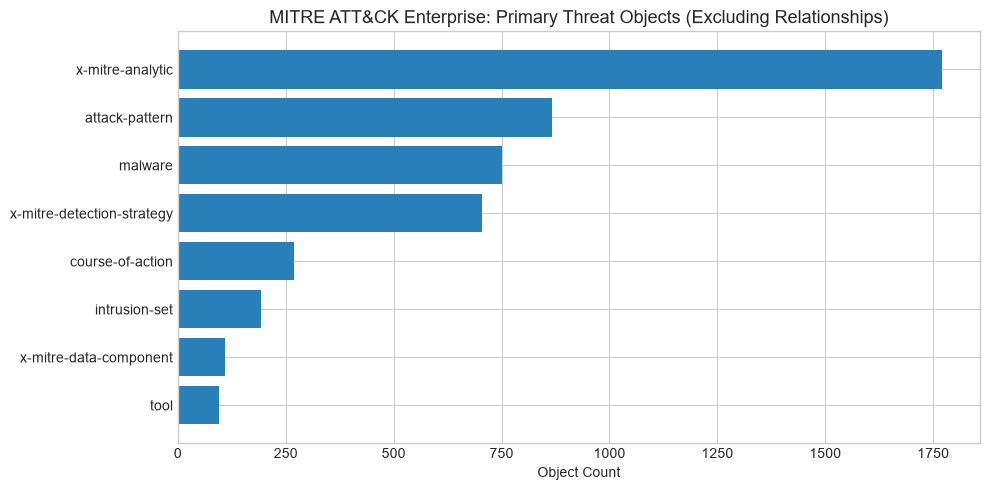

In [4]:
# 3.1 Object Type Breakdown
stix_objects = mitre_raw.get("objects", [])
type_counts = Counter(obj.get("type", "unknown") for obj in stix_objects)

type_df = pd.DataFrame([
    {"STIX Object Type": k, "Count": v, "Percentage": f"{(v / len(stix_objects))*100:.2f}%"}
    for k, v in type_counts.most_common()
])

print(f"Total STIX Objects in Enterprise Matrix: {len(stix_objects):,}")
display(type_df)

# Plot top STIX object categories
plt.figure(figsize=(10, 5))
top_types = type_df[type_df["STIX Object Type"] != "relationship"].head(8)
plt.barh(top_types["STIX Object Type"][::-1], top_types["Count"][::-1], color="#2980b9")
plt.title("MITRE ATT&CK Enterprise: Primary Threat Objects (Excluding Relationships)", fontsize=13)
plt.xlabel("Object Count")
plt.tight_layout()
plt.show()


In [5]:
# 3.2 Extract Attack Patterns (Techniques & Sub-techniques)
attack_patterns = [obj for obj in stix_objects if obj.get("type") == "attack-pattern" and not obj.get("revoked", False)]

techniques_list = []
for obj in attack_patterns:
    # Extract technique ID from external references (e.g. T1059)
    tech_id = "N/A"
    url = ""
    for ref in obj.get("external_references", []):
        if ref.get("source_name") == "mitre-attack":
            tech_id = ref.get("external_id", "N/A")
            url = ref.get("url", "")
            break
            
    # Extract Kill Chain Tactics
    tactics = [kc.get("phase_name") for kc in obj.get("kill_chain_phases", []) if kc.get("kill_chain_name") == "mitre-attack"]
    
    techniques_list.append({
        "Technique ID": tech_id,
        "Name": obj.get("name"),
        "Tactics": ", ".join(tactics),
        "Is Sub-Technique": obj.get("x_mitre_is_subtechnique", False),
        "Platforms": ", ".join(obj.get("x_mitre_platforms", [])),
        "Description Snippet": obj.get("description", "").split("\n")[0][:120] + "...",
        "URL": url
    })

tech_df = pd.DataFrame(techniques_list)
print(f"Total Active Attack Patterns: {len(tech_df)} (Sub-techniques: {sum(tech_df['Is Sub-Technique'])}, Primary: {len(tech_df) - sum(tech_df['Is Sub-Technique'])})")
tech_df.head(10)


Total Active Attack Patterns: 718 (Sub-techniques: 480, Primary: 238)


,Technique ID,Name,Tactics,Is Sub-Technique,Platforms,Description Snippet,URL
0,T1055.011,Extra Window Memory Injection,"stealth, privilege-escalation",True,Windows,Adversaries may inject malicious code into process via Extra Window Memory (EWM) in order to eva...,https://attack.mitre.org/techniques/T1055/011
1,T1053.005,Scheduled Task,"execution, persistence, privilege-escalation",True,Windows,Adversaries may abuse the Windows Task Scheduler to perform task scheduling for initial or recur...,https://attack.mitre.org/techniques/T1053/005
2,T1205.002,Socket Filters,"stealth, persistence, command-and-control",True,"Linux, macOS, Windows",Adversaries may attach filters to a network socket to monitor then activate backdoors used for p...,https://attack.mitre.org/techniques/T1205/002
3,T1560.001,Archive via Utility,collection,True,"Linux, macOS, Windows",Adversaries may use utilities to compress and/or encrypt collected data prior to exfiltration. M...,https://attack.mitre.org/techniques/T1560/001
4,T1021.005,VNC,lateral-movement,True,"Linux, Windows, macOS",Adversaries may use [Valid Accounts](https://attack.mitre.org/techniques/T1078) to remotely cont...,https://attack.mitre.org/techniques/T1021/005
5,T1047,Windows Management Instrumentation,execution,False,Windows,Adversaries may abuse Windows Management Instrumentation (WMI) to execute malicious commands and...,https://attack.mitre.org/techniques/T1047
6,T1687,Exploitation for Defense Impairment,defense-impairment,False,"IaaS, Linux, macOS, SaaS, Windows","Adversaries may exploit vulnerabilities in security software, infrastructure, or defensive compo...",https://attack.mitre.org/techniques/T1687
7,T1113,Screen Capture,collection,False,"Linux, macOS, Windows",Adversaries may attempt to take screen captures of the desktop to gather information over the co...,https://attack.mitre.org/techniques/T1113
8,T1027.011,Fileless Storage,stealth,True,"Linux, Windows","Adversaries may store data in ""fileless"" formats to conceal malicious activity from defenses. Fi...",https://attack.mitre.org/techniques/T1027/011
9,T1037,Boot or Logon Initialization Scripts,"persistence, privilege-escalation",False,"ESXi, Linux, macOS, Network Devices, Windows",Adversaries may use scripts automatically executed at boot or logon initialization to establish ...,https://attack.mitre.org/techniques/T1037


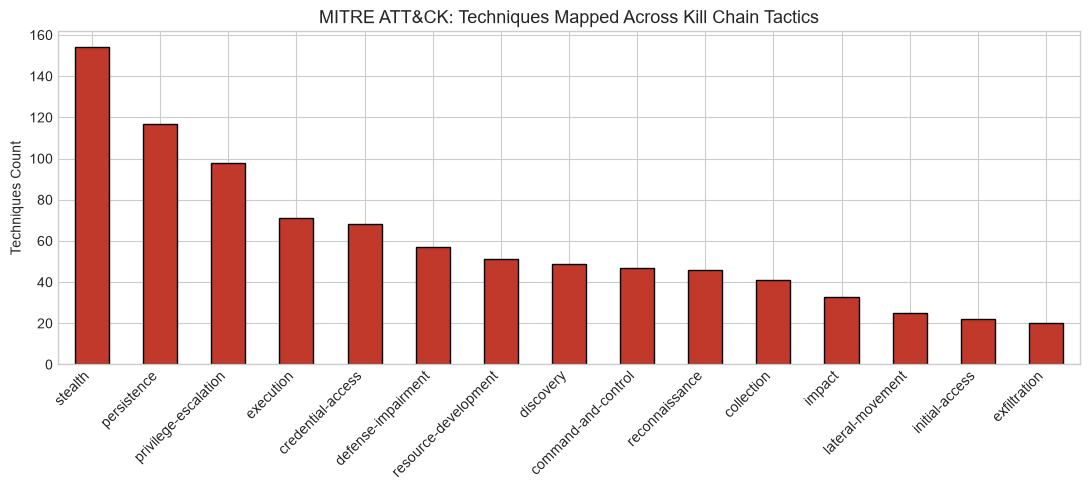

In [6]:
# 3.3 Tactics Distribution Analysis
all_tactics = []
for tactics_str in tech_df["Tactics"]:
    if tactics_str:
        all_tactics.extend([t.strip() for t in tactics_str.split(",")])

tactic_counts = pd.Series(all_tactics).value_counts()

plt.figure(figsize=(11, 5))
tactic_counts.plot(kind="bar", color="#c0392b", edgecolor="black")
plt.title("MITRE ATT&CK: Techniques Mapped Across Kill Chain Tactics", fontsize=13)
plt.ylabel("Techniques Count")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


---
### 4. CISA KEV (Known Exploited Vulnerabilities) Exploration

The **CISA KEV Catalog** tracks vulnerabilities that adversaries actively exploit in the wild. Unlike theoretical vulnerabilities, every CVE in this catalog represents an active, weaponized threat.

Key fields:
* **`cveID`**: Canonical Common Vulnerabilities and Exposures identifier.
* **`vendorProject`**: Vulnerable software publisher (e.g. Microsoft, Cisco, Apache).
* **`product`**: Impacted software product.
* **`vulnerabilityName`**: Human-readable vulnerability title.
* **`shortDescription`**: Root cause and impact summary.
* **`requiredAction`**: Remediation mandate for federal and enterprise networks.
* **`knownRansomwareCampaignUse`**: Indicates if the flaw is weaponized in ransomware playbooks.


In [7]:
# 4.1 CISA KEV Catalog Metadata & Overview
print("CISA KEV Catalog Metadata:")
print(f"  • Title:           {cisa_raw.get('title')}")
print(f"  • Catalog Version: {cisa_raw.get('catalogVersion')}")
print(f"  • Date Released:   {cisa_raw.get('dateReleased')}")
print(f"  • Total CVEs:      {cisa_raw.get('count'):,}")

cisa_vulns = cisa_raw.get("vulnerabilities", [])
cisa_df = pd.DataFrame(cisa_vulns)
print(f"\nLoaded DataFrame with shape: {cisa_df.shape}")
cisa_df.head(5)[["cveID", "vendorProject", "product", "vulnerabilityName", "dateAdded", "knownRansomwareCampaignUse"]]


CISA KEV Catalog Metadata:
  • Title:           CISA Catalog of Known Exploited Vulnerabilities
  • Catalog Version: 2026.10.13
  • Date Released:   2026-10-13T19:10:43.6568Z
  • Total CVEs:      1,741

Loaded DataFrame with shape: (1741, 12)


,cveID,vendorProject,product,vulnerabilityName,dateAdded,knownRansomwareCampaignUse
0,CVE-2026-104935,Ivanti,Connect Secure,Ivanti Connect Secure Authentication Bypass by Spoofing Vulnerability,2026-10-13,Unknown
1,CVE-2026-96951,Microsoft,Windows,Microsoft Windows Command Injection Vulnerability,2026-10-13,Unknown
2,CVE-2015-5477,ISC,BIND,ISC BIND Data Processing Errors Vulnerability,2026-10-08,Unknown
3,CVE-2016-3081,Apache,Struts,Apache Struts Command Injection Vulnerability,2026-10-08,Unknown
4,CVE-2023-22894,Strapi,Strapi,Strapi Cleartext Storage of Sensitive Information Vulnerability,2026-10-08,Unknown


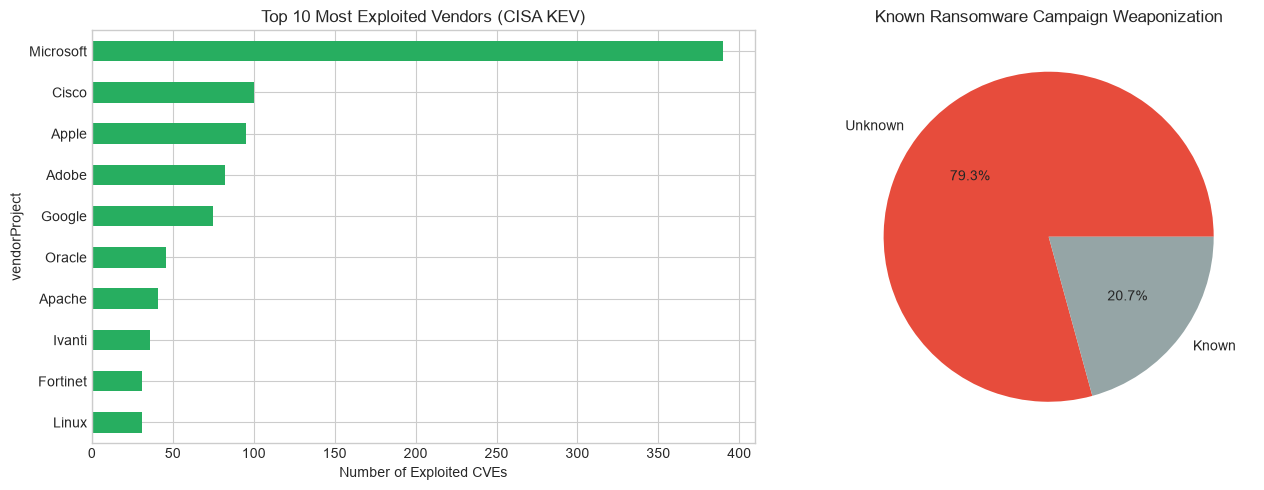

In [8]:
# 4.2 Top Targeted Vendors and Ransomware Associations
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Top 10 Targeted Vendors
top_vendors = cisa_df["vendorProject"].value_counts().head(10)
top_vendors.plot(kind="barh", ax=axes[0], color="#27ae60")
axes[0].set_title("Top 10 Most Exploited Vendors (CISA KEV)", fontsize=12)
axes[0].set_xlabel("Number of Exploited CVEs")
axes[0].invert_yaxis()

# Ransomware Association
ransomware_counts = cisa_df["knownRansomwareCampaignUse"].value_counts()
axes[1].pie(ransomware_counts, labels=ransomware_counts.index, autopct="%1.1f%%", colors=["#e74c3c", "#95a5a6"])
axes[1].set_title("Known Ransomware Campaign Weaponization", fontsize=12)

plt.tight_layout()
plt.show()


In [9]:
# 4.3 Preview Sample CISA Actionable Remediation Guidance
sample_kev = cisa_df.iloc[0]
print(f"Vulnerability: {sample_kev['cveID']} - {sample_kev['vulnerabilityName']}")
print(f"Vendor/Product: {sample_kev['vendorProject']} {sample_kev['product']}")
print(f"Date Added:     {sample_kev['dateAdded']} (Due Date: {sample_kev['dueDate']})")
print(f"Ransomware Use: {sample_kev['knownRansomwareCampaignUse']}")
print(f"\nDescription:\n{sample_kev['shortDescription']}")
print(f"\nRequired Action:\n{sample_kev['requiredAction']}")


Vulnerability: CVE-2026-104935 - Ivanti Connect Secure Authentication Bypass by Spoofing Vulnerability
Vendor/Product: Ivanti Connect Secure
Date Added:     2026-10-13 (Due Date: 2026-10-16)
Ransomware Use: Unknown

Description:
Ivanti Connect Secure contains an authentication bypass by spoofing vulnerability that allows a remote unauthenticated attacker to execute arbitrary commands.

Required Action:
Apply mitigations in accordance with vendor instructions, ensuring compliance with CISA’s BOD 26-04 Prioritizing Security Updates Based on Risk (see URL in Notes) guidance and CISA’s “Forensics Triage Requirements” (see URL in Notes). Follow applicable BOD 26-04 guidance for cloud services or discontinue use of the product if mitigations are unavailable. Stakeholders are responsible for evaluating each asset's internet exposure and ensuring adherence to BOD 26-04 patching guidelines.


---
### 5. NVD (National Vulnerability Database) Exploration

The **NVD** catalog provides in-depth technical risk scores, Common Weakness Enumeration (CWE) categories, and CVSS severity metrics.

In this experiment, we explore our sample dataset focusing on **SQL Injection (CWE-89)** flaws to analyze how NVD data should be parsed and chunked for semantic threat search.


In [10]:
# 5.1 Parse NVD Vulnerabilities
nvd_items = nvd_raw.get("vulnerabilities", [])
print(f"Total NVD Sample CVE Records: {len(nvd_items)}")

nvd_parsed = []
for item in nvd_items:
    cve = item.get("cve", {})
    cve_id = cve.get("id", "N/A")
    
    # Description
    desc_list = cve.get("descriptions", [])
    eng_desc = next((d.get("value") for d in desc_list if d.get("lang") == "en"), "")
    
    # Weaknesses (CWE)
    cwes = []
    for w in cve.get("weaknesses", []):
        for desc in w.get("description", []):
            if desc.get("lang") == "en":
                cwes.append(desc.get("value"))
                
    # Metrics (CVSS v2 or v3)
    metrics = cve.get("metrics", {})
    cvss_score = None
    severity = "UNKNOWN"
    
    if "cvssMetricV31" in metrics:
        data = metrics["cvssMetricV31"][0].get("cvssData", {})
        cvss_score = data.get("baseScore")
        severity = data.get("baseSeverity")
    elif "cvssMetricV2" in metrics:
        data = metrics["cvssMetricV2"][0].get("cvssData", {})
        cvss_score = data.get("baseScore")
        severity = metrics["cvssMetricV2"][0].get("baseSeverity", "N/A")
        
    nvd_parsed.append({
        "CVE ID": cve_id,
        "Published": cve.get("published", "")[:10],
        "CVSS Base Score": cvss_score,
        "Severity": severity,
        "CWEs": ", ".join(cwes) if cwes else "N/A",
        "Description": eng_desc[:120] + "..." if len(eng_desc) > 120 else eng_desc
    })

nvd_df = pd.DataFrame(nvd_parsed)
display(nvd_df)


Total NVD Sample CVE Records: 20


,CVE ID,Published,CVSS Base Score,Severity,CWEs,Description
0,CVE-2000-1233,2000-12-31,7.5,HIGH,NVD-CWE-Other,SQL injection vulnerability in read.php3 and other scripts in Phorum 3.0.7 allows remote attacke...
1,CVE-2000-1236,2000-12-31,7.5,HIGH,NVD-CWE-Other,SQL injection vulnerability in mod_sql in Oracle Internet Application Server (IAS) 3.0.7 and ear...
2,CVE-2001-1348,2001-05-28,7.5,HIGH,NVD-CWE-Other,TWIG 2.6.2 and earlier allows remote attackers to perform unauthorized database operations via a...
3,CVE-2001-1472,2001-08-03,4.6,MEDIUM,NVD-CWE-Other,SQL injection vulnerability in prefs.php in phpBB 1.4.0 and 1.4.1 allows remote authenticated us...
4,CVE-2001-1379,2001-08-29,7.5,HIGH,NVD-CWE-Other,"The PostgreSQL authentication modules (1) mod_auth_pgsql 0.9.5, and (2) mod_auth_pgsql_sys 0.9.4..."
5,CVE-2001-1402,2001-09-10,7.5,HIGH,NVD-CWE-Other,"Bugzilla before 2.14 does not properly escape untrusted parameters, which could allow remote att..."
6,CVE-2001-1460,2001-10-13,7.5,HIGH,NVD-CWE-Other,SQL injection vulnerability in article.php in PostNuke 0.62 through 0.64 allows remote attackers...
7,CVE-2001-1224,2001-12-23,7.5,HIGH,NVD-CWE-Other,get_input in adrotate.pm for Les VanBrunt AdRotate Pro 2.0 allows remote attackers to modify the...
8,CVE-2001-1482,2001-12-31,7.5,HIGH,NVD-CWE-Other,SQL injection vulnerability in bb_memberlist.php for phpBB 1.4.2 allows remote attackers to exec...
9,CVE-2002-0216,2002-05-16,5.0,MEDIUM,NVD-CWE-Other,userinfo.php in XOOPS 1.0 RC1 allows remote attackers to obtain sensitive information via a SQL ...


---
### 6. OWASP Documentation Exploration

The **OWASP Top 10 (2025 Release)** provides comprehensive security engineering frameworks for web applications. Unlike structured JSON feeds (MITRE/CISA/NVD), OWASP data is stored as rich **Markdown documentation** containing:
* Executive summaries
* Description of vulnerability mechanics
* Code examples and attack scenarios
* Defense and remediation guidelines
* References to relevant CWEs and NIST standards


In [11]:
# 6.1 Discover and Inspect OWASP Top 10 (2025) Markdown Files
owasp_docs = []

for file_path in owasp_files:
    fname = os.path.basename(file_path)
    # Filter primary Top 10 files (e.g. A01 through A10)
    with open(file_path, "r", encoding="utf-8") as f:
        content = f.read()
        
    lines = content.splitlines()
    title = lines[0].replace("#", "").strip() if lines else fname
    
    # Count sections (H2 and H3 headings)
    h2_sections = re.findall(r"^##\s+(.+)$", content, re.MULTILINE)
    h3_sections = re.findall(r"^###\s+(.+)$", content, re.MULTILINE)
    
    # Approximate token count (1 word ≈ 1.3 tokens)
    word_count = len(content.split())
    est_tokens = int(word_count * 1.3)
    
    is_top10 = bool(re.match(r"^A\d{2}_2025", fname))
    
    owasp_docs.append({
        "Filename": fname,
        "Document Title": title,
        "Is Core Top 10": is_top10,
        "Word Count": word_count,
        "Est. Tokens": est_tokens,
        "H2 Sections": len(h2_sections),
        "Section Headings": ", ".join(h2_sections[:4])
    })

owasp_df = pd.DataFrame(owasp_docs)
print(f"Discovered {len(owasp_df)} documentation files in OWASP 2025 repository:")
display(owasp_df[owasp_df["Is Core Top 10"]].reset_index(drop=True))


Discovered 16 documentation files in OWASP 2025 repository:


,Filename,Document Title,Is Core Top 10,Word Count,Est. Tokens,H2 Sections,Section Headings
0,A01_2025-Broken_Access_Control.md,A01:2025 Broken Access Control ![icon](../assets/TOP_10_Icons_Final_Broken_Access_Control.png){:...,True,1067,1387,7,"Background. , Score table., Description. , How to prevent."
1,A02_2025-Security_Misconfiguration.md,A02:2025 Security Misconfiguration ![icon](../assets/TOP_10_Icons_Final_Security_Misconfiguratio...,True,901,1171,7,"Background. , Score table., Description. , How to prevent."
2,A03_2025-Software_Supply_Chain_Failures.md,A03:2025 Software Supply Chain Failures ![icon](../assets/TOP_10_Icons_Final_Vulnerable_Outdated...,True,1447,1881,7,"Background., Score table., Description., How to prevent."
3,A04_2025-Cryptographic_Failures.md,A04:2025 Cryptographic Failures ![icon](../assets/TOP_10_Icons_Final_Crypto_Failures.png){: styl...,True,1486,1931,7,"Background. , Score table., Description. , How to prevent."
4,A05_2025-Injection.md,"A05:2025 Injection ![icon](../assets/TOP_10_Icons_Final_Injection.png){: style=""height:80px;widt...",True,1259,1636,7,"Background. , Score table., Description. , How to prevent."
5,A06_2025-Insecure_Design.md,"A06:2025 Insecure Design ![icon](../assets/TOP_10_Icons_Final_Insecure_Design.png){: style=""heig...",True,1441,1873,7,"Background. , Score table., Description. , How to prevent."
6,A07_2025-Authentication_Failures.md,A07:2025 Authentication Failures ![icon](../assets/TOP_10_Icons_Final_Identification_and_Authent...,True,1275,1657,7,"Background. , Score table., Description. , How to prevent."
7,A08_2025-Software_or_Data_Integrity_Failures.md,A08:2025 Software or Data Integrity Failures ![icon](../assets/TOP_10_Icons_Final_Software_and_D...,True,932,1211,7,"Background. , Score table., Description. , How to prevent."
8,A09_2025-Security_Logging_and_Alerting_Failures.md,A09:2025 Security Logging & Alerting Failures ![icon](../assets/TOP_10_Icons_Final_Security_Logg...,True,1198,1557,7,"Background. , Score table., Description. , How to prevent."
9,A10_2025-Mishandling_of_Exceptional_Conditions.md,A10:2025 Mishandling of Exceptional Conditions ![icon](../assets/TOP_10_Icons_Final_Mishandling_...,True,1282,1666,7,"Background. , Score table., Description. , How to prevent."


In [12]:
# 6.2 Deep Dive into A06:2025 - Injection Document Structure
injection_file = os.path.join(OWASP_DIR, "A06_2025-Injection.md")

if os.path.exists(injection_file):
    with open(injection_file, "r", encoding="utf-8") as f:
        injection_text = f.read()
        
    print("=" * 80)
    print("  STRUCTURE OF OWASP A06:2025 - INJECTION")
    print("=" * 80)
    print(f"Total Words: {len(injection_text.split()):,} | Total Characters: {len(injection_text):,}")
    print("\nHeadings Discovered (Optimal RAG Chunk Boundaries):")
    for heading in re.findall(r"^(#{1,3}\s+.+)$", injection_text, re.MULTILINE):
        print("  ", heading)
        
    print("\nFirst 400 Characters of Document:")
    print("-" * 50)
    print(injection_text[:400] + "...")
else:
    print(f"[!] File not found: {injection_file}")


[!] File not found: C:\Users\himma\Desktop\Projects\AI project\SentinelAI\intelligence\data\raw\owasp\repository\2025\docs\en\A06_2025-Injection.md


---
### 7. Initial Findings and Observations

After exploring all four threat intelligence sources, we synthesize key architectural observations to design our **RAG chunking, embedding, and retrieval pipeline**:

#### 7.1 Cross-Source Comparison Matrix

| Knowledge Source | Primary Format | Total Records | Primary Granularity | Optimal Chunking Strategy | RAG Retrieval Role |
| :--- | :---: | :---: | :---: | :---: | :---: |
| **MITRE ATT&CK** | STIX 2.1 JSON | $26,690$ Objects | Technique / Sub-technique | **Entity-Level Chunking**: 1 chunk per attack pattern with tactical metadata | Threat Attribution & TTP Mapping |
| **CISA KEV** | Flat JSON Catalog | $1,741$ CVEs | CVE Vulnerability | **Entity-Level Chunking**: 1 chunk per CVE with vendor/product/remediation | Active Weaponization & Threat Verification |
| **NVD** | CVE JSON API | 20 Samples | CVE / CWE Metric | **Field-Level Chunking**: CVE ID + Description + CVSS Score + CWE tags | Technical Vulnerability Profiling |
| **OWASP Top 10** | Markdown | 16 Documents ($~1.5\text{k}$ tokens each) | Application Risk Category | **Semantic Heading Chunking**: Split by `##` headings ($300-500$ tokens/chunk) | Defense Playbooks & Architectural Remediation |

---

#### 7.2 Key Architectural Takeaways for SentinelAI:

1. **Heterogeneous Document Types**:
   * Knowledge is split between **atomic structured records** (MITRE, CISA, NVD) and **long-form narrative documentation** (OWASP).
   * A single generic chunking method (e.g. fixed 500-token chunks with no metadata) will fail. Structured sources need **entity-level chunking**, while Markdown needs **hierarchical heading-aware chunking**.

2. **Metadata Enrichment is Essential**:
   * Every chunk stored in ChromaDB/vector store must retain searchable metadata fields:
     * `source` (`mitre`, `cisa`, `nvd`, `owasp`)
     * `technique_id` (e.g., `T1059`, `T1498`)
     * `cve_id` (e.g., `CVE-2026-104935`)
     * `attack_family` (mapping directly to SentinelAI's 9 ML categories: `DDoS`, `Infiltration`, `Botnet`, etc.)
     * `severity` (`CRITICAL`, `HIGH`, `MEDIUM`)

3. **Bridge from ML Detection to RAG Reasoning**:
   * When the Stage 08 microservice intercepts an intrusion (e.g. `Infiltration` via lateral SMB copying), our RAG agent will query:
     1. MITRE ATT&CK for technique `T1021.002` (SMB/Windows Admin Shares).
     2. CISA KEV for recent SMB zero-day exploits.
     3. OWASP/NVD for prevention and active host isolation playbooks.


In [13]:
# Summary Matrix Verification
comparison_data = [
    {
        "Knowledge Base": "MITRE ATT&CK",
        "Record Count": f"{len(stix_objects):,} STIX Objects",
        "Active Techniques": len(tech_df),
        "Optimal Chunking": "Entity Chunk (1 Technique per Document)",
        "Key Metadata": "Technique ID, Tactic, Platform, URL"
    },
    {
        "Knowledge Base": "CISA KEV",
        "Record Count": f"{len(cisa_df):,} CVEs",
        "Active Techniques": "N/A (Software Vulnerabilities)",
        "Optimal Chunking": "Entity Chunk (1 CVE per Document)",
        "Key Metadata": "CVE ID, Vendor, Product, Ransomware Flag"
    },
    {
        "Knowledge Base": "NVD",
        "Record Count": f"{len(nvd_df):,} Sample CVEs",
        "Active Techniques": "CWE-89 Mappings",
        "Optimal Chunking": "Field Chunk (CVE + CVSS + CWE)",
        "Key Metadata": "CVE ID, Base Score, Severity, CWE"
    },
    {
        "Knowledge Base": "OWASP Top 10",
        "Record Count": f"{len(owasp_df)} Markdown Docs",
        "Active Techniques": "10 Risk Categories",
        "Optimal Chunking": "Semantic Heading Split (300-500 Tokens)",
        "Key Metadata": "Category Code, Document Title, Section"
    }
]

summary_df = pd.DataFrame(comparison_data)
display(summary_df)
print("\n[SUCCESS] Stage 01 Threat Intelligence Exploration Complete.")


,Knowledge Base,Record Count,Active Techniques,Optimal Chunking,Key Metadata
0,MITRE ATT&CK,"26,690 STIX Objects",718,Entity Chunk (1 Technique per Document),"Technique ID, Tactic, Platform, URL"
1,CISA KEV,"1,741 CVEs",N/A (Software Vulnerabilities),Entity Chunk (1 CVE per Document),"CVE ID, Vendor, Product, Ransomware Flag"
2,NVD,20 Sample CVEs,CWE-89 Mappings,Field Chunk (CVE + CVSS + CWE),"CVE ID, Base Score, Severity, CWE"
3,OWASP Top 10,16 Markdown Docs,10 Risk Categories,Semantic Heading Split (300-500 Tokens),"Category Code, Document Title, Section"



[SUCCESS] Stage 01 Threat Intelligence Exploration Complete.
